### rc_test3_silo

Applying the optimised ESN implementation in 'optimised_rc' on multiple locations from each of the GRDC  Sub-Regions 
- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1  

-- Normalisation applied to data sourced
-- Developed plots for use in Mid-Year Presentation

--- Date:   May 2026

In [17]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
from great_tables import GT
import seaborn as sns
from matplotlib.colors import LogNorm  

In [ ]:
def collect_data(form,lat,lon,start,finish,username,password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')


In [ ]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')
    
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass
    
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

def prepare_data(df):
    """
    preparing rainfall and cumulative growing degree set variables 
    - perform smoothing on rainfall observations through rolling window average
    - normalise rainfall observations
    - extract normalised rain and gddc vectors
    """
    clean = clean_data(df)
    clean['Rain.Mean'] = clean.Rain.rolling(window=180,min_periods=1).mean()
    clean_rain = clean[['Rain.Mean']].values
    clean_gddc = clean[['GDD.C']].values
    normalised_rain = []
    min_val = min(clean_rain)
    max_val = max(clean_rain)
    diff = max_val - min_val
    for x in clean_rain:
        normalised_rain.append((x - min_val) / diff)
    return np.array(normalised_rain), clean_gddc


In [ ]:
start_date = '19710101'
end_date = '20260327'

## Kwinana East Port Zone ##
# Merredin (10092)
merre_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_rain, merre_gddc = prepare_data(merre_data)

# Noongaar (12064)
noon_data = collect_data('standard','-31.33','118.97',start_date,end_date,'email@gmail.com')
noon_rain, noon_gddc = prepare_data(noon_data)

# Wialki (10135)
wia_data = collect_data('standard','-30.49','118.13',start_date,end_date,'email@gmail.com')
wia_rain, wia_gddc = prepare_data(wia_data)

# Wongan Hills (8137)
wongan_data = collect_data('standard','-30.89','116.72',start_date,end_date,'email@gmail.com')
wongan_rain, wongan_gddc = prepare_data(wongan_data)

# Bullfinch (12011)
bull_data = collect_data('standard','-30.98','119.07',start_date,end_date,'email@gmail.com')
bull_rain, bull_gddc = prepare_data(bull_data)


## Kwinana West Port Zone ##
# Northam (10111) 
northam_data = collect_data('standard','-31.65','116.66',start_date,end_date,'email@gmail.com')
northam_rain, northam_gddc = prepare_data(northam_data)

# Dalwallinu North (8014)
dal_data = collect_data('standard','-30.22','116.78',start_date,end_date,'email@gmail.com')
dal_rain, dal_gddc = prepare_data(dal_data)

# Pingelly (10626)
ping_data = collect_data('standard','-32.53','117.08',start_date,end_date,'email@gmail.com')
ping_rain, ping_gddc = prepare_data(ping_data)

# Narrogin (10614)
narro_data = collect_data('standard','-32.93','117.18',start_date,end_date,'email@gmail.com')
narro_rain, narro_gddc = prepare_data(narro_data)

# Corrigin (10536)
corri_data = collect_data('standard','-32.33','117.87',start_date,end_date,'email@gmail.com')
corri_rain, corri_gddc = prepare_data(corri_data)


## Geraldton Port Zone ##
# Northampton (8100) 
nh_data = collect_data('standard','-28.36','114.63',start_date,end_date,'email@gmail.com')
nh_rain, nh_gddc = prepare_data(nh_data)

# Mullewa (8095)
mull_data = collect_data('standard','-28.54','115.51',start_date,end_date,'email@gmail.com')
mull_rain, mull_gddc = prepare_data(mull_data)

# Three Springs (8121)
threesp_data = collect_data('standard','-29.53','115.76',start_date,end_date,'email@gmail.com')
threesp_rain, threesp_gddc = prepare_data(threesp_data)

# Coorow (8037)
coorow_data = collect_data('standard','-29.88','116.02',start_date,end_date,'email@gmail.com')
coorow_rain, coorow_gddc = prepare_data(coorow_data)

# Eradu (8200)
eradu_data = collect_data('standard','-28.69','115.04',start_date,end_date,'email@gmail.com')
eradu_rain, eradu_gddc = prepare_data(eradu_data)

## Esperance Port Zone ##
# Esperance (9789) 
esperance_data = collect_data('standard','-33.83','121.89',start_date,end_date,'email@gmail.com')
esperance_rain, esperance_gddc = prepare_data(esperance_data)

# Ravensthorpe (10633)
raven_data = collect_data('standard','-33.58','120.05',start_date,end_date,'email@gmail.com')
raven_rain, raven_gddc = prepare_data(raven_data)

# Salmon Gums Res.Stn. (12071)
salmon_data = collect_data('standard','-32.99','121.62',start_date,end_date,'email@gmail.com')
salmon_rain, salmon_gddc = prepare_data(salmon_data)

# Katta Barega (12312)
katta_data = collect_data('standard','-33.59','122.45',start_date,end_date,'email@gmail.com')
katta_rain, katta_gddc = prepare_data(katta_data)

# Erinair (9772)
erin_data = collect_data('standard','-33.76','121.22',start_date,end_date,'email@gmail.com')
erin_rain, erin_gddc = prepare_data(erin_data)


## Albany Port Zone ##
# Albany (9500) 
albany_data = collect_data('standard','-35.03','117.88',start_date,end_date,'email@gmail.com')
albany_rain, albany_gddc = prepare_data(albany_data)

# Illalangi (9523)
illa_data = collect_data('standard','-34.97','117.27',start_date,end_date,'email@gmail.com')
illa_rain, illa_gddc = prepare_data(illa_data)

# Cranbrook (10537)
cran_data = collect_data('standard','-34.30','117.55',start_date,end_date,'email@gmail.com')
cran_rain, cran_gddc = prepare_data(cran_data)

# Kojonup (10582)
kojo_data = collect_data('standard','-33.83','117.16',start_date,end_date,'email@gmail.com')
kojo_rain, kojo_gddc = prepare_data(kojo_data)

# Cape Riche (9520)
cape_data = collect_data('standard','-34.61','118.75',start_date,end_date,'email@gmail.com')
cape_rain, cape_gddc = prepare_data(cape_data)


In [ ]:
class ESN:
    """
    N: number of nodes 
    d: average number of connections per node
    rho: spectral radius
    split: proportion of data to take as training  
    """
    def __init__(self, N, d, rho):
        self.N = N
        self.d = d
        self.rho = rho

        # random, sparse, reservoir weights:
        ## connections between nodes decided by probability of d/N
        # sampling from normal distribution provides random weight values.
        Weights = np.multiply(
            np.random.binomial(size=(self.N,self.N), p=self.d/self.N, n=1),
            np.random.normal(size=(self.N,self.N))) 

        # rescale so that rho = largest absolutel eigenvalue (maintaining echo state property)
        self.Vadj = Weights * (self.rho/np.max(np.absolute(np.linalg.eig(Weights)[0])))

        # input matrix: maps the scalar input to every node of the reservoir
        self.Vin = np.random.uniform(-1,1,size=(self.N,1))

        # bias matrix: bias added to each node's activation
        self.Vbias = np.random.uniform(-1,1,size=(self.N,))

    def run_reservoir(self,input_data):
        """
        drive the reservoir using the input_data and return the state at every timestep
        states = (len(input_data), N)
        """
        states = np.zeros((len(input_data), self.N))
        for i in range(1, len(input_data)):
            # feed previous state through the weights with the input and bias
            # use sigmoidal tanh to condense values
            states[i, :] = np.tanh(np.matmul(self.Vadj, states[i-1, :]) + np.matmul(self.Vin,input_data[i]) + self.Vbias)
        return states        

    def train(self, train_input, train_target, washout, beta=0.01):
        """
        fit the output weights
        - remove the initial washout period from the states and target 
        - compute Vout through ridge regression
        """
        train_states = self.run_reservoir(train_input)
        train_states = train_states[washout:]
        train_target = train_target[washout:]
        N, t = np.shape(train_states.T)

        # using ridge regression to compute the output weights through training
        self.Vout = np.dot(np.dot(train_target.T,train_states), 
                           np.linalg.pinv(np.dot(train_states.T, train_states)+ beta*np.identity(N)))


    def predict(self, test_input, washout):
        """
        run reservoir on test data and map states to predictions
        - remove initial washout period from states and testing input
        - compute Root Mean Squared Error of predictions 
        """
        test_states = self.run_reservoir(test_input)

        # apply trained linear readout
        predictions = np.dot(test_states, self.Vout.T)

        # compute RMSE of predictions
        rmse = np.sqrt(((predictions[washout:] - test_input[washout:])**2).mean())

        return predictions, rmse
    


In [ ]:
def splitting_data(rain,gddc,step):
    """
    function to split rainfall and cumulative growing degree days by step size
    80% of data for training, 20% for testing
    """
    # step to decide how far prediction goes
    train_size = int(len(rain) * 0.8)
    train_input = rain[:train_size]
    train_target = rain[step:train_size+step]
    test_target = rain[train_size+step:]
    x_values = gddc[train_size+step:]

    return train_input, train_target, test_target, x_values

def plotting_data(x_values, test_actual, test_predictions, title):
    """
    function to plot the resulting predictions against the actual data
    """
    plt.plot(x_values,test_actual, label = 'actual_values',color='blue',)
    plt.plot(x_values, test_predictions, label='predicted',color='green',alpha=0.6)
    plt.xlabel('Cumulative Growing Degree Days (°C Days)')
    plt.ylabel('Standardised Rain (mm)')
    plt.title(title)
    plt.legend(['Actual Values', 'Prediction'])
    plt.show()

def rc_for_location(location, rain, gddc, step, nodes=100, connections=5, rho=0.9):
    """
    function run the ESN prediction and return RMSE 
    """
    train_input, train_target, test_target, x_vals = splitting_data(rain, gddc, step)
    esn = ESN(nodes,connections,rho)
    esn.train(train_input, train_target, washout=100)
    rain_pred, rmse = esn.predict(test_target, washout=10)

    return rmse


def rc_for_location_withplot(location, rain, gddc, step, nodes=100, connections=5, rho=0.9):
    """
    function to generate predictions for a particular given location and step size and produce plot
    """
    train_input, train_target, test_target, x_vals = splitting_data(rain, gddc, step)
    # create the ESN
    esn = ESN(nodes,connections,rho)
    # train the ESN 
    esn.train(train_input, train_target, washout=100)
    # testing washout is fixed at 10 
    rain_pred, rmse = esn.predict(test_target, washout=10)
    # plot the data with washout of 10
    plotting_data(x_vals[10:], test_target[10:], rain_pred[10:], title=location+" "+str(step)+" step(s) Prediction")

    return rmse

## Kwinana East Port Zone ##

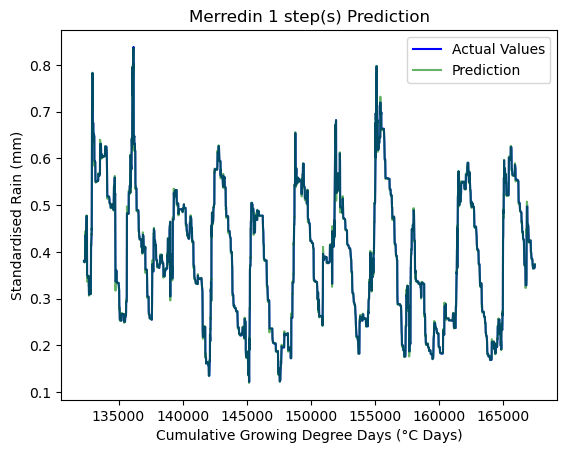

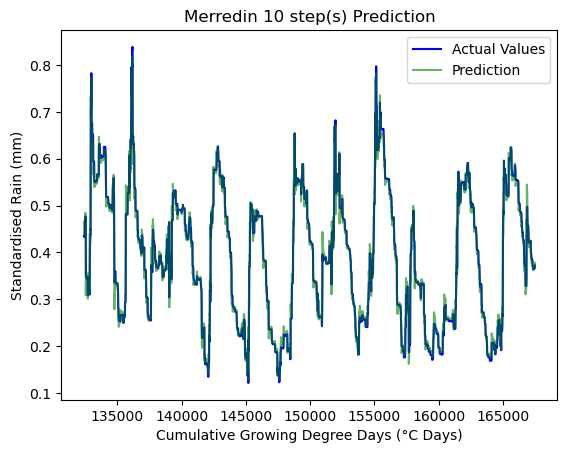

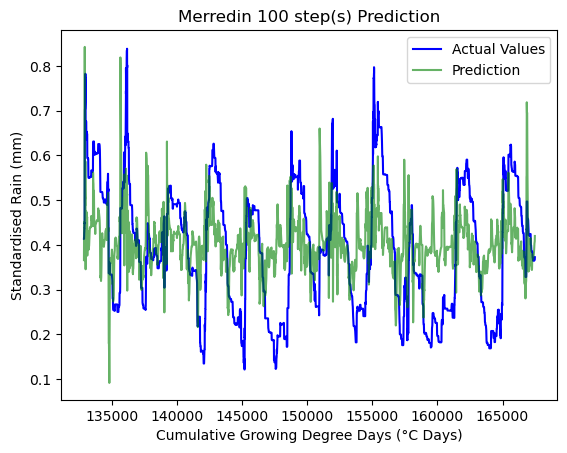

In [23]:
# Merredin (10092)
merre_rmse_1step = rc_for_location_withplot('Merredin', merre_rain, merre_gddc, step=1)
merre_rmse_10step = rc_for_location_withplot('Merredin', merre_rain, merre_gddc, step=10)
merre_rmse_100step = rc_for_location_withplot('Merredin', merre_rain, merre_gddc, step=100)

# Noongaar (12064)
noon_rmse_1step = rc_for_location('Noongaar', noon_rain, noon_gddc, step=1)
noon_rmse_10step = rc_for_location('Noongaar', noon_rain, noon_gddc, step=10)
noon_rmse_100step = rc_for_location('Noongaar', noon_rain, noon_gddc, step=100)

# Wialki (10135)
wia_rmse_1step = rc_for_location('Wialki', wia_rain, wia_gddc, step=1)
wia_rmse_10step = rc_for_location('Wialki', wia_rain, wia_gddc, step=10)
wia_rmse_100step = rc_for_location('Wialki', wia_rain, wia_gddc, step=100)

# Wongan Hills (8137)
wongan_rmse_1step = rc_for_location('Wongan Hills', wongan_rain, wongan_gddc, step=1)
wongan_rmse_10step = rc_for_location('Wongan Hills', wongan_rain, wongan_gddc, step=10)
wongan_rmse_100step = rc_for_location('Wongan Hills', wongan_rain, wongan_gddc, step=100)

# Bullfinch (12011)
bull_rmse_1step = rc_for_location('Bullfinch', bull_rain, bull_gddc, step=1)
bull_rmse_10step = rc_for_location('Bullfinch', bull_rain, bull_gddc, step=10)
bull_rmse_100step = rc_for_location('Bullfinch', bull_rain, bull_gddc, step=100)


## Kwinana West Port Zone ##

In [24]:
# Northam (10111) 
nor_rmse_1step = rc_for_location('Northam', northam_rain, northam_gddc, step=1)
nor_rmse_10step = rc_for_location('Northam', northam_rain, northam_gddc, step=10)
nor_rmse_100step = rc_for_location('Northam', northam_rain, northam_gddc, step=100)

# Dalwallinu North (8014)
dal_rmse_1step = rc_for_location('Dalwallinu (North)', dal_rain, dal_gddc, step=1)
dal_rmse_10step = rc_for_location('Dalwallinu (North)', dal_rain, dal_gddc, step=10)
dal_rmse_100step = rc_for_location('Dalwallinu (North)', dal_rain, dal_gddc, step=100)


# Pingelly (10626)
ping_rmse_1step = rc_for_location('Pingelly', ping_rain, ping_gddc, step=1)
ping_rmse_10step = rc_for_location('Pingelly)', ping_rain, ping_gddc, step=10)
ping_rmse_100step = rc_for_location('Pingelly', ping_rain, ping_gddc, step=100)


# Narrogin (10614)
narro_rmse_1step = rc_for_location('Narrogin', narro_rain, narro_gddc, step=1)
narro_rmse_10step = rc_for_location('Narrogin)', narro_rain, narro_gddc, step=10)
narro_rmse_100step = rc_for_location('Narrogin', narro_rain, narro_gddc, step=100)

# Corrigin (10536)
corri_rmse_1step = rc_for_location('Corrigin', corri_rain, corri_gddc, step=1)
corri_rmse_10step = rc_for_location('Corrigin)', corri_rain, corri_gddc, step=10)
corri_rmse_100step = rc_for_location('Corrigin', corri_rain, corri_gddc, step=100)

In [25]:
## Geraldton Port Zone ##

# Northampton (8100) 
nh_rmse_1step = rc_for_location('Northampton', nh_rain, nh_gddc, step=1)
nh_rmse_10step = rc_for_location('Northampton', nh_rain, nh_gddc, step=10)
nh_rmse_100step = rc_for_location('Northampton', nh_rain, nh_gddc, step=100)


# Mullewa (8095)
mull_rmse_1step = rc_for_location('Mullewa', mull_rain, mull_gddc, step=1)
mull_rmse_10step = rc_for_location('Mullewa', mull_rain, mull_gddc, step=10)
mull_rmse_100step = rc_for_location('Mullewa', mull_rain, mull_gddc, step=100)


# Three Springs (8121)
threesp_rmse_1step = rc_for_location('Three Springs', threesp_rain, threesp_gddc, step=1)
threesp_rmse_10step = rc_for_location('Three Springs', threesp_rain, threesp_gddc, step=10)
threesp_rmse_100step = rc_for_location('Three Springs', threesp_rain, threesp_gddc, step=100)

# Coorow (8037)
coorow_rmse_1step = rc_for_location('Coorow', coorow_rain, coorow_gddc, step=1)
coorow_rmse_10step = rc_for_location('Coorow', coorow_rain, coorow_gddc, step=10)
coorow_rmse_100step = rc_for_location('Coorow', coorow_rain, coorow_gddc, step=100)

# Eradu (8200)
eradu_rmse_1step = rc_for_location('Eradu', eradu_rain, eradu_gddc, step=1)
eradu_rmse_10step = rc_for_location('Eradu', eradu_rain, eradu_gddc, step=10)
eradu_rmse_100step = rc_for_location('Eradu', eradu_rain, eradu_gddc, step=100)


In [26]:
## Esperance Port Zone ##
# Esperance (9789) 
esp_rmse_1step = rc_for_location('Esperance', esperance_rain, esperance_gddc, step=1)
esp_rmse_10step = rc_for_location('Esperance', esperance_rain, esperance_gddc, step=10)
esp_rmse_100step = rc_for_location('Esperance', esperance_rain, esperance_gddc, step=100)

# Ravensthorpe (10633)
raven_rmse_1step = rc_for_location('Ravensthorpe', raven_rain, raven_gddc, step=1)
raven_rmse_10step = rc_for_location('Ravensthorpe', raven_rain, raven_gddc, step=10)
raven_rmse_100step = rc_for_location('Ravensthorpe', raven_rain, raven_gddc, step=100)

# Salmon Gums Res.Stn. (12071)
salmon_rmse_1step = rc_for_location('Salmon Gums Res.Stn', salmon_rain, salmon_gddc, step=1)
salmon_rmse_10step = rc_for_location('Salmon Gums Res.Stn', salmon_rain, salmon_gddc, step=10)
salmon_rmse_100step = rc_for_location('Salmon Gums Res.Stn', salmon_rain, salmon_gddc, step=100)

# Katta Barega (12312)
katta_rmse_1step = rc_for_location('Katta Barega', katta_rain, katta_gddc, step=1)
katta_rmse_10step = rc_for_location('Katta Barega', katta_rain, katta_gddc, step=10)
katta_rmse_100step = rc_for_location('Katta Barega', katta_rain, katta_gddc, step=100)

# Erinair (9772)
erin_rmse_1step = rc_for_location('Erinair', erin_rain, erin_gddc, step=1)
erin_rmse_10step = rc_for_location('Erinair', erin_rain, erin_gddc, step=10)
erin_rmse_100step = rc_for_location('Erinair', erin_rain, erin_gddc, step=100)

In [27]:
## Albany Port Zone ##
# Albany (9500) 
alb_rmse_1step = rc_for_location('Albany', albany_rain, albany_gddc, step=1)
alb_rmse_10step = rc_for_location('Albany', albany_rain, albany_gddc, step=10)
alb_rmse_100step = rc_for_location('Albany', albany_rain, albany_gddc, step=100)


# Illalangi (9523)
illa_rmse_1step = rc_for_location('Illalangi', illa_rain, illa_gddc, step=1)
illa_rmse_10step = rc_for_location('Illalangi', illa_rain, illa_gddc, step=10)
illa_rmse_100step = rc_for_location('Illalangi', illa_rain, illa_gddc, step=100)


# Cranbrook (10537)
cran_rmse_1step = rc_for_location('Cranbrook', cran_rain, cran_gddc, step=1)
cran_rmse_10step = rc_for_location('Cranbrook', cran_rain, cran_gddc, step=10)
cran_rmse_100step = rc_for_location('Cranbrook', cran_rain, cran_gddc, step=100)

# Kojonup (10582)
kojo_rmse_1step = rc_for_location('Kojonup', kojo_rain, kojo_gddc, step=1)
kojo_rmse_10step = rc_for_location('Kojonup', kojo_rain, kojo_gddc, step=10)
kojo_rmse_100step = rc_for_location('Kojonup', kojo_rain, kojo_gddc, step=100)

# Cape Riche (9520)
cape_rmse_1step = rc_for_location('Cape Riche', cape_rain, cape_gddc, step=1)
cape_rmse_10step = rc_for_location('Cape Riche', cape_rain, cape_gddc, step=10)
cape_rmse_100step = rc_for_location('Cape Riche', cape_rain, cape_gddc, step=100)



In [ ]:
step1 = [merre_rmse_1step, noon_rmse_1step, wia_rmse_1step, wongan_rmse_1step, bull_rmse_1step,
               nor_rmse_1step, dal_rmse_1step, ping_rmse_1step,narro_rmse_1step, corri_rmse_1step,
               nh_rmse_1step, mull_rmse_1step, threesp_rmse_1step,coorow_rmse_1step, eradu_rmse_1step,
               esp_rmse_1step, raven_rmse_1step,salmon_rmse_1step,katta_rmse_1step, erin_rmse_1step,
               alb_rmse_1step,illa_rmse_1step,cran_rmse_1step,kojo_rmse_1step,cape_rmse_1step]
step10 = [merre_rmse_10step, noon_rmse_10step, wia_rmse_10step, wongan_rmse_10step, bull_rmse_10step,
               nor_rmse_10step, dal_rmse_10step, ping_rmse_10step,narro_rmse_10step, corri_rmse_10step,
               nh_rmse_10step, mull_rmse_10step, threesp_rmse_10step,coorow_rmse_10step, eradu_rmse_10step,
               esp_rmse_10step, raven_rmse_10step,salmon_rmse_10step,katta_rmse_10step, erin_rmse_10step,
               alb_rmse_10step,illa_rmse_10step,cran_rmse_10step,kojo_rmse_10step,cape_rmse_10step]
step100 = [merre_rmse_100step, noon_rmse_100step, wia_rmse_100step, wongan_rmse_100step, bull_rmse_100step,
                 nor_rmse_100step, dal_rmse_100step, ping_rmse_100step, narro_rmse_100step, corri_rmse_100step,
                 nh_rmse_100step, mull_rmse_100step, threesp_rmse_100step, coorow_rmse_100step, eradu_rmse_100step,
                 esp_rmse_100step, raven_rmse_100step, salmon_rmse_100step, katta_rmse_100step, erin_rmse_100step,
                 alb_rmse_100step, illa_rmse_100step, cran_rmse_100step, kojo_rmse_100step, cape_rmse_100step]

# creating a dictionary with resulting RMSE scores for each of the locations within the zones at the 3 step sizes.
rmse = {
    'Zone': np.repeat(['Kwinana East Port Zone','Kwinana West Port Zone', 'Geraldton Port Zone', 'Esperance Port Zone', 'Albany Port Zone'], 5), 
    'Location': ['Merredin','Noongaar', 'Wialki','Wongan Hills', 'Bullfinch',
                 'Northam','Dalwallinu (North)','Pingelly', 'Narrogin','Corrigin',
                 'Northampton','Mullewa','Three Springs','Coorow','Eradu',
                 'Esperance','Ravensthorpe','Salmon Gums Res.Stn','Katta Barega','Erinair',
                 'Albany','Illalangi','Cranbrook','Kojonup','Cape Riche'],
    '1 Step': [round(x, 4) for x in step1],
    '10 Steps': [round(x, 4) for x in step10],
    '100 Steps': [round(x, 4) for x in step100]
}

# plotting a table
rmse_df = pd.DataFrame(data=rmse)

(
    GT(rmse_df, rowname_col="Location", groupname_col="Zone")
    .tab_header(
        title="Echo State Network RMSE"
    )
    .tab_spanner(label="Forward Prediction", columns=["1 Step", "10 Steps", "100 Steps"])
)



GT(_tbl_data=                      Zone             Location  1 Step  10 Steps  100 Steps
0   Kwinana East Port Zone             Merredin  0.0021    0.0095     0.1335
1   Kwinana East Port Zone             Noongaar  0.0012    0.0046     0.0569
2   Kwinana East Port Zone               Wialki  0.0025    0.0095     0.1118
3   Kwinana East Port Zone         Wongan Hills  0.0026    0.0125     0.1630
4   Kwinana East Port Zone            Bullfinch  0.0010    0.0032     0.0375
5   Kwinana West Port Zone              Northam  0.0028    0.0159     0.2033
6   Kwinana West Port Zone   Dalwallinu (North)  0.0023    0.0104     0.1217
7   Kwinana West Port Zone             Pingelly  0.0011    0.0063     0.0958
8   Kwinana West Port Zone             Narrogin  0.0009    0.0045     0.0649
9   Kwinana West Port Zone             Corrigin  0.0022    0.0127     0.1572
10     Geraldton Port Zone          Northampton  0.0029    0.0180     0.2285
11     Geraldton Port Zone              Mullewa  0.0028    0.0130     0.1565
12     Geraldton Port Zone        Three Springs  0.0025    0.0180     0.1978
13     Geraldton Port Zone               Coorow  0.0021    0.0125     0.1603
14     Geraldton Port Zone                Eradu  0.0029    0.0195     0.2020
15     Esperance Port Zone            Esperance  0.0027    0.0176     0.1935
16     Esperance Port Zone         Ravensthorpe  0.0030    0.0104     0.1315
17     Esperance Port Zone  Salmon Gums Res.Stn  0.0022    0.0078     0.0889
18     Esperance Port Zone         Katta Barega  0.0025    0.0088     0.1301
19     Esperance Port Zone              Erinair  0.0033    0.0132     0.1639
20        Albany Port Zone               Albany  0.0031    0.0193     0.2670
21        Albany Port Zone            Illalangi  0.0031    0.0214     0.2412
22        Albany Port Zone            Cranbrook  0.0005    0.0026     0.0337
23        Albany Port Zone              Kojonup  0.0029    0.0164     0.2112
24        Albany Port Zone           Cape Riche  0.0008    0.0033     0.0505, _body=<great_tables._gt_data.Body object at 0x178a72c40>, _boxhead=Boxhead([ColInfo(var='Zone', type=<ColInfoTypeEnum.row_group: 3>, column_label='Zone', column_align='left', column_width=None), ColInfo(var='Location', type=<ColInfoTypeEnum.stub: 2>, column_label='Location', column_align='left', column_width=None), ColInfo(var='1 Step', type=<ColInfoTypeEnum.default: 1>, column_label='1 Step', column_align='right', column_width=None), ColInfo(var='10 Steps', type=<ColInfoTypeEnum.default: 1>, column_label='10 Steps', column_align='right', column_width=None), ColInfo(var='100 Steps', type=<ColInfoTypeEnum.default: 1>, column_label='100 Steps', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x17d7e3d90>, _spanners=Spanners([SpannerInfo(spanner_id='Forward Prediction', spanner_level=0, spanner_label='Forward Prediction', spanner_units=None, spanner_pattern=None, vars=['1 Step', '10 Steps', '100 Steps'], built=None)]), _heading=Heading(title='Echo State Network RMSE', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x17d85d810>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x178a71cd0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x17d85d950>, _formats=[], _substitutions=[], _col_merge=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), ta

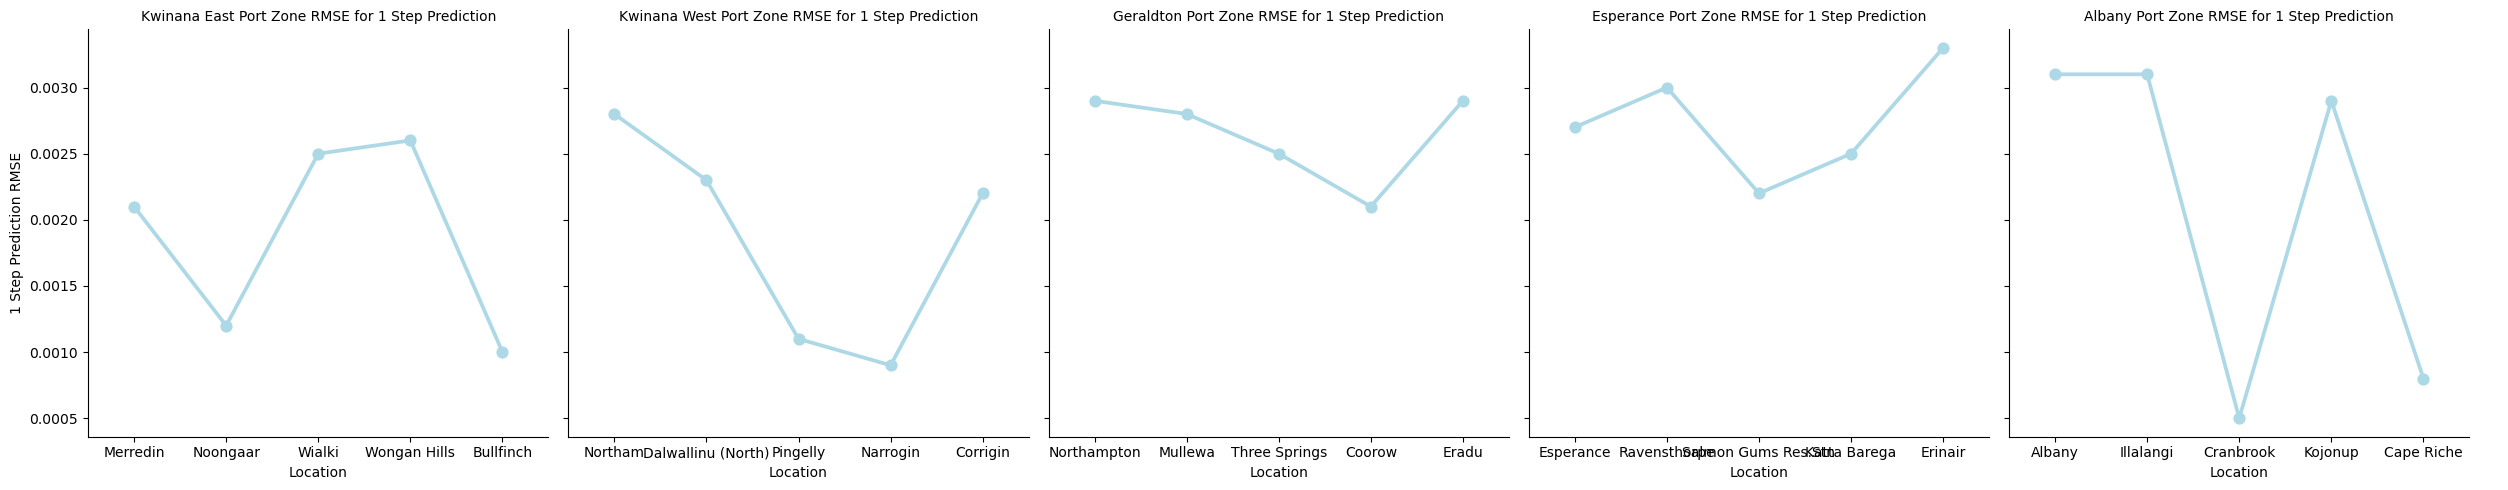

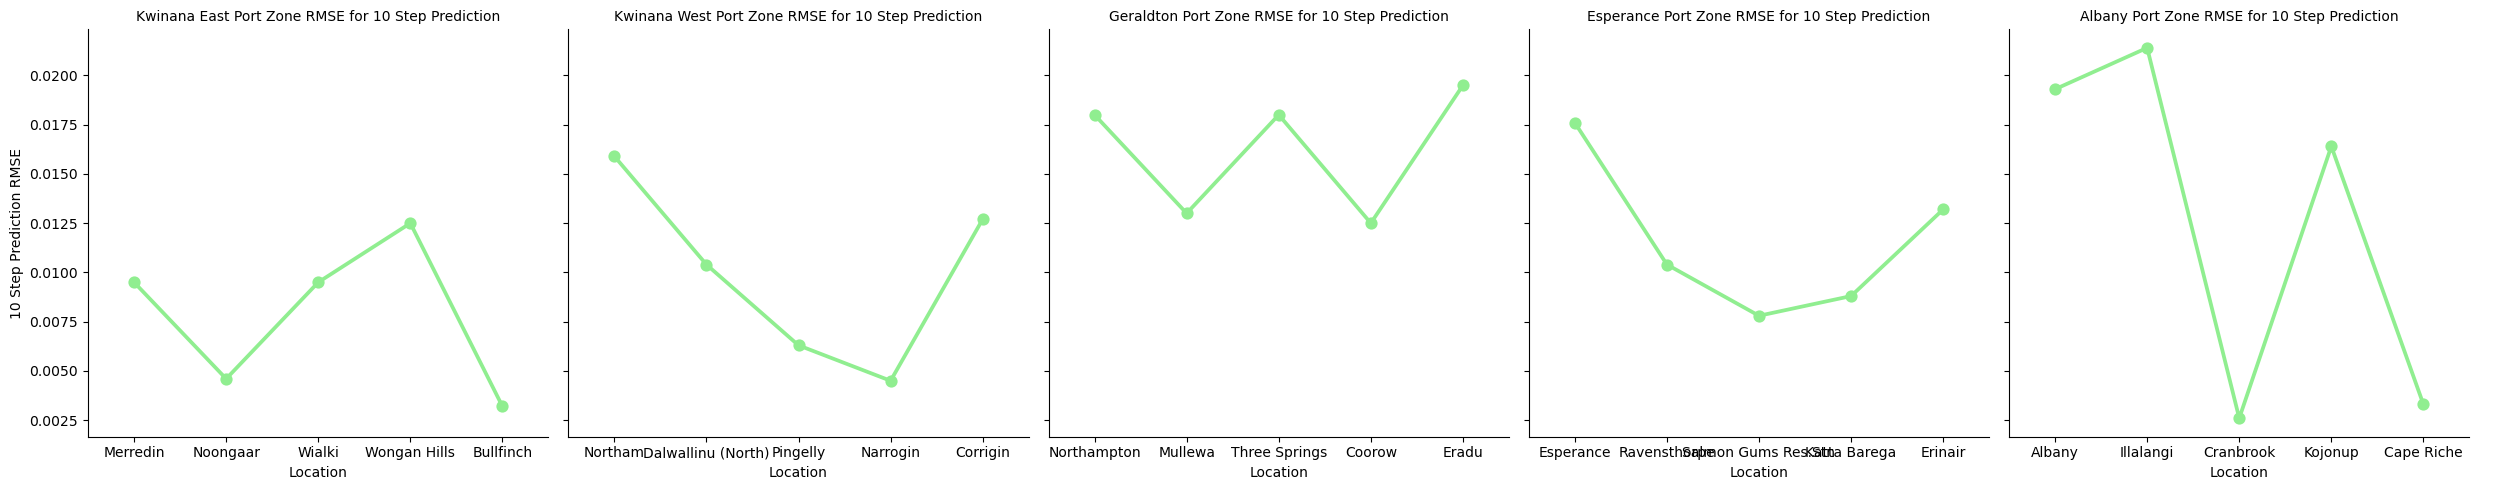

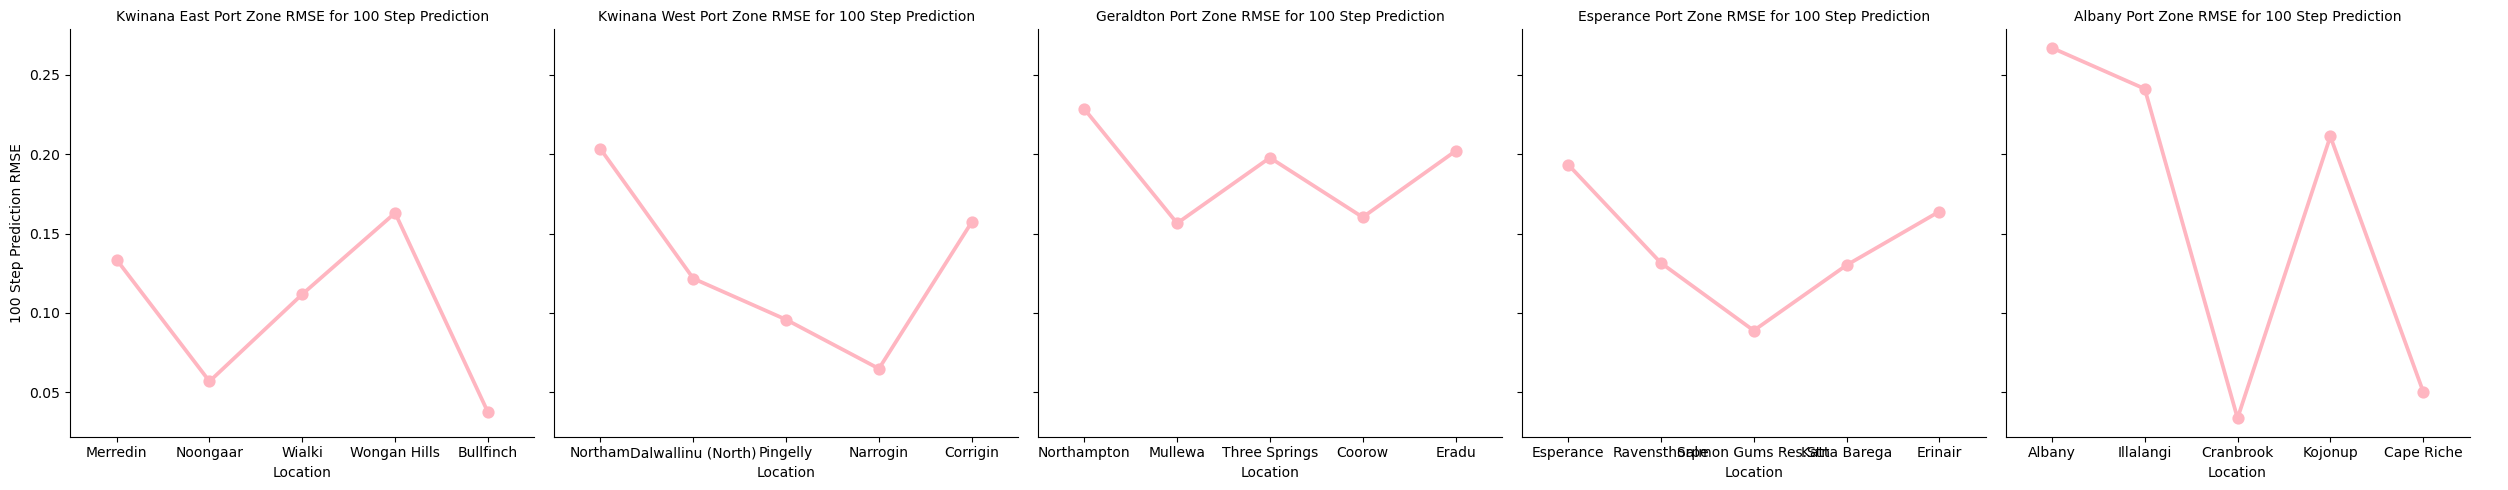

In [ ]:
# exploring different potential plot types to use

step1_rmse_plot = sns.catplot(data = rmse, x='Location',y='1 Step',col='Zone', sharex=False, kind="point", color='lightblue')
step1_rmse_plot.set_titles("{col_name} RMSE for 1 Step Prediction")
step1_rmse_plot.set_ylabels("1 Step Prediction RMSE")

step10_rmse_plot = sns.catplot(data = rmse, x='Location',y='10 Steps',col='Zone', sharex=False, kind="point", color='lightgreen')
step10_rmse_plot.set_titles("{col_name} RMSE for 10 Step Prediction")
step10_rmse_plot.set_ylabels("10 Step Prediction RMSE")

step100_rmse_plot = sns.catplot(data = rmse, x='Location',y='100 Steps',col='Zone', sharex=False, kind="point", color='lightpink')
step100_rmse_plot.set_titles("{col_name} RMSE for 100 Step Prediction")
step100_rmse_plot.set_ylabels("100 Step Prediction RMSE")

/var/folders/zy/g7r_7kl93ll2v309pt6_9ts80000gn/T/ipykernel_52740/3456562109.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/var/folders/zy/g7r_7kl93ll2v309pt6_9ts80000gn/T/ipykernel_52740/3456562109.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/var/folders/zy/g7r_7kl93ll2v309pt6_9ts80000gn/T/ipykernel_52740/3456562109.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


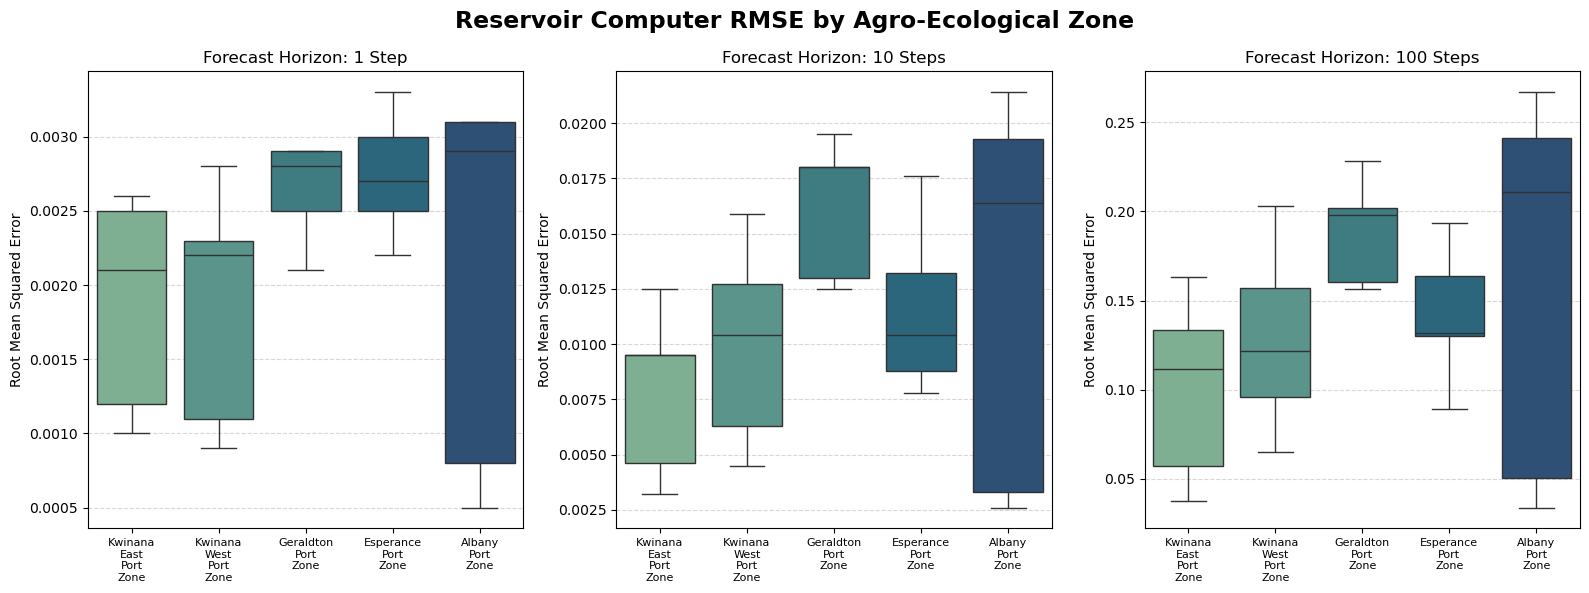

In [ ]:
# development of a boxplot showing initial results for mid-year presentation

rmse_long = rmse_df.melt(
    id_vars=['Zone', 'Location'],
    value_vars=['1 Step', '10 Steps', '100 Steps'],
    var_name='Forecast Horizon',
    value_name='Root Mean Squared Error'
)

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=False)

horizons = ['1 Step', '10 Steps', '100 Steps']
palette  = "crest"

for ax, horizon in zip(axes, horizons):
    subset = rmse_long[rmse_long['Forecast Horizon'] == horizon]
    
    sns.boxplot(
        data=subset,
        x='Zone',
        y='Root Mean Squared Error',
        palette=palette,
        hue='Zone',
        legend=False,
        ax=ax
    )
    
    ax.set_title(f'Forecast Horizon: {horizon}', fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel('Root Mean Squared Error', fontsize=10)
    ax.set_xticklabels(
        [label.get_text().replace(' ', '\n') for label in ax.get_xticklabels()],
        fontsize=8
    )
    ax.grid(axis='y', linestyle='--', alpha=0.5)

fig.suptitle('Reservoir Computer RMSE by Agro-Ecological Zone', fontsize=17, fontweight='bold')
plt.tight_layout()
plt.savefig('rmse_boxplots_seaborn.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()